In [3]:
import yfinance as yf
import pandas as pd

symbol = "ES=F"          # E-mini S&P 500 futures (use "^GSPC" for the S&P 500 index)
start  = "2010-01-01"
end    = None            # None = up to today

df = yf.download(symbol, start=start, end=end, auto_adjust=True)

# Flatten multi-level columns (newer yfinance versions)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

print(df.head())

# Save to disk
df.to_csv("ES_F_2010_present.csv")

[*********************100%***********************]  1 of 1 completed


Price         Close     High      Low     Open   Volume
Date                                                   
2010-01-04  1128.75  1129.75  1113.25  1113.75  1291254
2010-01-05  1132.25  1133.00  1125.00  1128.50  1378593
2010-01-06  1133.00  1135.50  1127.25  1132.00  1259921
2010-01-07  1137.50  1138.75  1127.00  1133.00  1567025
2010-01-08  1141.50  1141.75  1131.00  1137.25  1527666


In [9]:
%pip install pandas-ta-classic

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,1128.75,1129.75,1113.25,1113.75,1291254
2010-01-05,1132.25,1133.00,1125.00,1128.50,1378593
2010-01-06,1133.00,1135.50,1127.25,1132.00,1259921
2010-01-07,1137.50,1138.75,1127.00,1133.00,1567025
2010-01-08,1141.50,1141.75,1131.00,1137.25,1527666


In [10]:
import pandas as pd
import pandas_ta_classic as ta

def _merge(df_main, ta_obj):
    """Add TA output to df_main, regardless of Series/DataFrame type."""
    if isinstance(ta_obj, pd.DataFrame):
        return pd.concat([df_main, ta_obj], axis=1)
    else:
        return pd.concat([df_main, ta_obj.rename(ta_obj.name)], axis=1)


def add_indicators(data: pd.DataFrame) -> pd.DataFrame:
    df = data.copy()

    # ── Momentum ──────────────────────────────
    for length in [5, 10, 15]:
        df[f"rsi_{length}"] = ta.rsi(df["Close"], length=length)
    df["roc_10"] = ta.roc(df["Close"], length=10)
    df["mom_10"] = ta.mom(df["Close"], length=10)

    # ── Oscillators ───────────────────────────
    df = _merge(df, ta.stochrsi(df["Close"]))
    df["cci_20"] = ta.cci(df["High"], df["Low"], df["Close"], length=20)
    df["wr_14"] = ta.willr(df["High"], df["Low"], df["Close"], length=14)
    df = _merge(df, ta.kst(df["Close"]))
    df["macd"] = ta.macd(df["Close"])["MACD_12_26_9"]

    # ── Trend ─────────────────────────────────
    for length in [5, 10, 20]:
        df[f"sma_{length}"] = ta.sma(df["Close"], length=length)
        df[f"ema_{length}"] = ta.ema(df["Close"], length=length)
    df["vwma_20"] = ta.vwma(df["Close"], df["Volume"], length=20)

    # ── Volatility ────────────────────────────
    df = _merge(df, ta.bbands(df["Close"], length=20))
    df["atr_14"] = ta.atr(df["High"], df["Low"], df["Close"], length=14)
    df = _merge(df, ta.kc(df["High"], df["Low"], df["Close"], length=20))

    return df

In [11]:
df_ta = add_indicators(df)
df_ta.tail()

,Close,High,Low,Open,Volume,rsi_5,rsi_10,rsi_15,roc_10,mom_10,...,vwma_20,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_14,KCLe_20_2,KCBe_20_2,KCUe_20_2
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-12,7858.00,7887.00,7846.25,7873.00,927661,65.025393,61.876071,59.703577,1.436086,111.25,...,7771.084958,7582.063460,7761.705005,7941.346550,4.628920,0.768020,73.720111,7634.654428,7779.559121,7924.463814
2026-10-13,7855.75,7864.00,7834.50,7855.50,1192792,63.844305,61.440828,59.448481,1.600491,123.75,...,7780.685895,7609.556113,7775.030005,7940.503896,4.256547,0.743906,70.561532,7650.092101,7786.815395,7923.538689
2026-10-14,7770.25,7879.75,7741.00,7856.25,2063500,34.273943,47.371659,50.639259,0.709611,54.75,...,7783.617611,7653.891046,7785.717505,7917.543964,3.386366,0.441334,75.432137,7635.107139,7785.237738,7935.368338
2026-10-15,7791.00,7801.75,7717.25,7768.25,1909800,42.371170,50.432348,52.470621,0.867426,67.00,...,7785.361988,7679.649425,7793.267505,7906.885584,2.915801,0.490021,76.079841,7633.858840,7785.786525,7937.714210
2026-10-16,7704.25,7809.50,7676.00,7788.75,2287988,25.776141,39.705754,44.993169,-0.938635,-73.00,...,7785.442864,7691.799269,7795.612500,7899.425731,2.663376,0.059967,80.181281,7615.134189,7778.021142,7940.908095


In [13]:
import numpy as np

def generate_label(
    data: pd.DataFrame,
    lookahead: int = 5,
    thresh: float = 0.01,
    col: str = "Close"
) -> pd.Series:
    """
    Label each row from the mean of the "next" `lookahead` closes:
      2 : future_mean >= current * (1 + thresh)
      1 : future_mean <= current * (1 - thresh)
      0 : otherwise
    """
    future_mean = (
        data[col]
        .shift(-lookahead)
        .rolling(window=lookahead, min_periods=lookahead)
        .mean()
    )
    # data["means"] = future_mean
    pct_change = (future_mean - data[col]) / data[col]

    labels = np.select(
        [pct_change >= thresh, pct_change <= -thresh],
        [2, 1],
        default=0
    )

    return pd.Series(labels, index=data.index)

lookheads = [2,4,6,8,10]
thresholds = [0.01,0.02]

for la in lookheads:
    for th in thresholds:
        df_ta[f"label_la{la}_th{th:.3f}"] = generate_label(df_ta,lookahead=la , thresh=th)

df_ta.dropna(inplace=True)
df_ta.head()

,Close,High,Low,Open,Volume,rsi_5,rsi_10,rsi_15,roc_10,mom_10,...,label_la2_th0.010,label_la2_th0.020,label_la4_th0.010,label_la4_th0.020,label_la6_th0.010,label_la6_th0.020,label_la8_th0.010,label_la8_th0.020,label_la10_th0.010,label_la10_th0.020
Date,,,,,,,,,,,,,,,,,,,,,
2010-03-19,1172.949951,1170.00,1164.75,1166.25,2165925,96.887722,87.409632,77.514562,3.207211,36.449951,...,0,0,0,0,0,0,0,0,0,0
2010-03-22,1162.000000,1163.25,1146.75,1150.75,1915804,60.663874,70.149881,67.826322,2.198769,25.000000,...,0,0,0,0,0,0,0,0,0,0
2010-03-23,1169.500000,1170.50,1159.00,1161.75,1856410,70.202149,74.049542,70.529424,2.542744,29.000000,...,0,0,0,0,0,0,0,0,0,0
2010-03-24,1164.500000,1170.00,1161.00,1169.25,1992386,58.401158,67.515931,66.536477,1.636483,18.750000,...,0,0,0,0,0,0,0,0,0,0
2010-03-25,1162.750000,1176.50,1160.25,1164.25,2355473,54.400349,65.276123,65.153259,1.064754,12.250000,...,0,0,0,0,0,0,0,0,2,0


In [16]:
split_idx = int(len(df_ta)*0.6)
split_idx_val = int(len(df_ta)*0.8)
train_df , test_df = df_ta.iloc[:split_idx],df_ta.iloc[split_idx_val]
feature_cols = [c for c in df_ta.columns if c not in ["open","high","low","Adj close","Volume"] and not c.startswith("label_")]
print("Total features :" , len(feature_cols))

Total features : 32


In [18]:
%pip install xgboost scikit-learn

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.1 MB/s eta 0:00:44
    --------------------------------------- 0.8/48.9 MB 1.3 MB/s eta 0:00:36
    --------------------------------------- 1.0/48.9 MB 1.2 MB/s eta 0:00:40
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:33
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:33
   - -------------------------------------- 2.1/48.9 MB 1.4 MB/s eta 0:00:33
   -- ------------------------------------- 2.6/48.9 MB 1.6 MB/s eta 0:00:30
   -- ------------------------------------- 2.9/48.9 MB 1.6 MB/s eta 0:00:29
   -- ------------------------------------- 3.4/48.9 MB 1.6 MB/s eta 0:00:28
   -- ------------------------------------- 3.7/48.9 MB 1.7 MB/s eta 0:00:28
   --- -------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

label_cols   = [c for c in df_ta.columns if c.startswith("label_")]
feature_cols = [c for c in df_ta.columns if not c.startswith("label_")]

# Chronological split with a gap so overlapping label windows don't leak
lookahead = 10                      # use your largest lookahead value
split = int(len(df_ta) * 0.8)
train_df = df_ta.iloc[:split]
test_df  = df_ta.iloc[split + lookahead:]   # slice, not a single row

assert isinstance(test_df, pd.DataFrame) and len(test_df) > 1, "test_df must be a multi-row DataFrame"

results = []

for label_col in label_cols:
    X_train, y_train = train_df[feature_cols], train_df[label_col]
    X_test,  y_test  = test_df[feature_cols],  test_df[label_col]

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=3,
        n_jobs=-1,
        eval_metric='mlogloss',
        seed=42
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    results.append({
        "label": label_col,
        "accuracy": accuracy_score(y_test, preds),
        "f1_macro": f1_score(y_test, preds, average='macro')
    })

pd.DataFrame(results).sort_values("accuracy", ascending=False).head(10)

,label,accuracy,f1_macro
1,label_la2_th0.020,0.952727,0.351920
3,label_la4_th0.020,0.848485,0.356578
5,label_la6_th0.020,0.793939,0.357614
7,label_la8_th0.020,0.766061,0.347809
0,label_la2_th0.010,0.671515,0.364414
9,label_la10_th0.020,0.656970,0.331500
2,label_la4_th0.010,0.558788,0.366247
4,label_la6_th0.010,0.470303,0.345192
6,label_la8_th0.010,0.288485,0.255534
8,label_la10_th0.010,0.207273,0.176887


In [22]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import classification_report, accuracy_score, f1_score
from xgboost import XGBClassifier

best_label = max(results, key=lambda x: x["f1_macro"])["label"]
print("Best label:", best_label)

X_train, y_train = train_df[feature_cols], train_df[best_label]
X_test,  y_test  = test_df[feature_cols],  test_df[best_label]

param_grid = {
    "n_estimators":     [200, 400, 600],
    "max_depth":        [4, 6, 8],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}
tscv = TimeSeriesSplit(n_splits=5)

xgb = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_jobs=-1,
    eval_metric='mlogloss',
    seed=42
)

grid = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=tscv,
    scoring='accuracy',
    verbose=1,
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

best_model = grid.best_estimator_
test_preds = best_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, test_preds))
print("Test macro F1:", f1_score(y_test, test_preds, average="macro"))
print(classification_report(y_test, test_preds, target_names=["range (0)", "down (1)", "up (2)"]))

Best label: label_la4_th0.010
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best params: {'colsample_bytree': 0.6, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 200, 'subsample': 1.0}
Best CV accuracy: 0.6395683453237411
Test accuracy: 0.6509090909090909
Test macro F1: 0.33704278812974464
              precision    recall  f1-score   support

   range (0)       0.70      0.94      0.80       549
    down (1)       0.23      0.19      0.21       106
      up (2)       0.00      0.00      0.00       170

    accuracy                           0.65       825
   macro avg       0.31      0.38      0.34       825
weighted avg       0.50      0.65      0.56       825



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [25]:
half = len(test_df) // 2
gap = 10   # >= your largest lookahead

val_df  = test_df.iloc[half + gap:]
test_df = test_df.iloc[:half]

print(len(test_df), len(val_df))

412 403


In [26]:
X_val, y_val = val_df[feature_cols], val_df[best_label]
val_preds = best_model.predict(X_val)
print(classification_report(y_val, val_preds))

              precision    recall  f1-score   support

           0       0.71      0.91      0.80       272
           1       0.20      0.23      0.22        48
           2       0.00      0.00      0.00        83

    accuracy                           0.64       403
   macro avg       0.30      0.38      0.34       403
weighted avg       0.50      0.64      0.56       403



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [32]:
import numpy as np

THRESH_1 = 0.55   # class 1 (bearish sell)
THRESH_2 = 0.55   # class 2 (bullish buy)


def custom_select(proba, thr1=0.65, thr2=0.65, neutral_label=0):
    pred = np.full(len(proba), neutral_label, dtype=int)

    mask1 = (proba[:, 1] >= thr1) & (proba[:, 1] > proba[:, 2])
    pred[mask1] = 1

    mask2 = (proba[:, 2] >= thr2) & (proba[:, 2] > proba[:, 1])
    pred[mask2] = 2

    return pred

In [33]:
X_train, y_train = train_df[feature_cols], train_df[best_label]
X_test,  y_test  = test_df[feature_cols],  test_df[best_label]

y_proba = best_model.predict_proba(X_test)
sel_preds = custom_select(y_proba, THRESH_1, THRESH_2)

test_df = test_df.copy()
test_df["sel_preds"] = sel_preds
print(classification_report(y_test, sel_preds))

y_proba = best_model.predict_proba(X_val)
sel_preds = custom_select(y_proba, THRESH_1, THRESH_2)

val_df = val_df.copy()
val_df["sel_preds"] = sel_preds
print(classification_report(y_val, sel_preds))

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

              precision    recall  f1-score   support

           0       0.66      1.00      0.80       272
           1       0.00      0.00      0.00        53
           2       0.00      0.00      0.00        87

    accuracy                           0.66       412
   macro avg       0.22      0.33      0.27       412
weighted avg       0.44      0.66      0.53       412

              precision    recall  f1-score   support

           0       0.67      1.00      0.81       272
           1       0.00      0.00      0.00        48
           2       0.00      0.00      0.00        83

    accuracy                           0.67       403
   macro avg       0.22      0.33      0.27       403
weighted avg       0.46      0.67      0.54       403



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [37]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 342.2 kB/s eta 0:00:01
   ------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


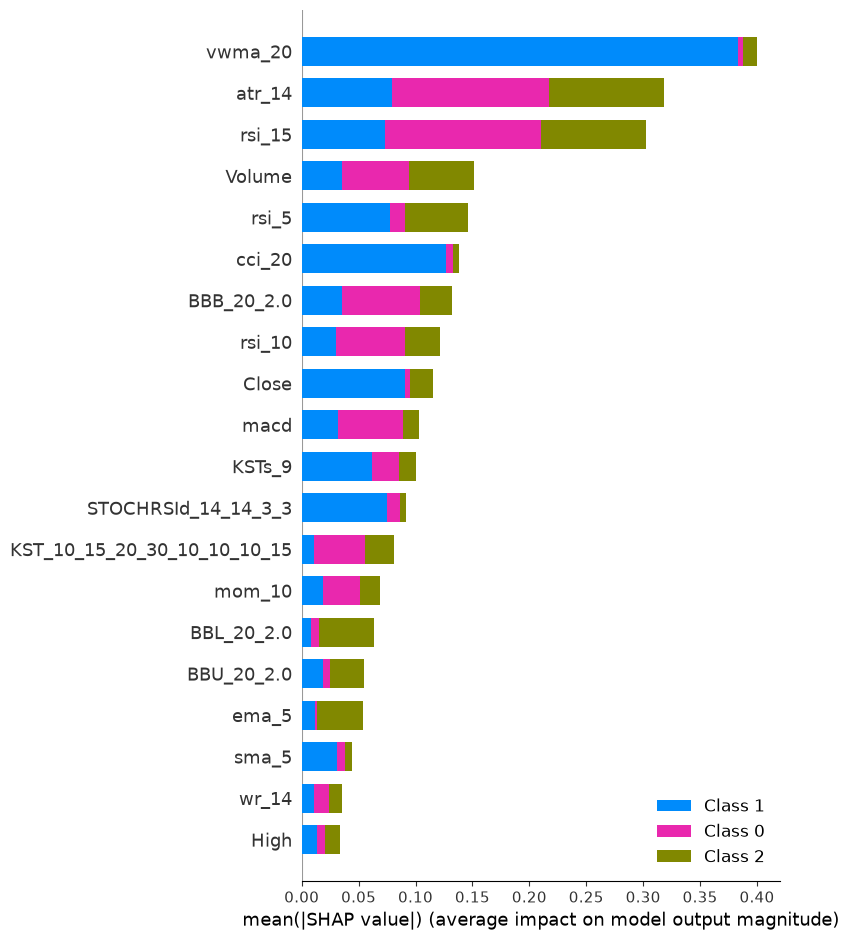

In [39]:
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_val)
shap.summary_plot(shap_values, X_val, plot_type="bar")

In [40]:
val_df["predictions"] = best_model.predict(X_val)

In [42]:
%pip install plotly nbformat

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 1.1 MB/s eta 0:00:09
   --- ------------------------------------ 0.8/9.7 MB 1.2 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.7 MB 1.2 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.7 MB 1.2 MB/s eta 0:00:08
   ----- ---------------------------------- 1.3/9.7 MB 1.0 MB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.7 MB 999.0 kB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.7 MB 999.0 kB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.7 MB 923.6 kB/s eta 0:00:09
   -------- ------------------------------- 2.1/9.7 MB 939.6 kB/s eta 0:00:09
   -------- ------------------------------- 2.1/9.7 MB 939.6 kB/s eta 0:00:09
   --------- ----------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import plotly.graph_objs as go

def plot_signals(test_df, pred_column='predictions', start=0, length=100):
    """
    Plot OHLC candles from test_df with:
    • purple dots for model signals
    • EMA line
    """
    # Subset
    df_slice = test_df.iloc[start:start+length].copy()
    df_slice.reset_index(inplace=True)  # Reset for plotting

    # Candle plot
    fig = go.Figure(data=[go.Candlestick(
        x=df_slice['index'] if 'index' in df_slice else df_slice.index,
        open=df_slice['Open'],
        high=df_slice['High'],
        low=df_slice['Low'],
        close=df_slice['Close'],
        name='Candles'
    )])

    
    if 'ema' in df_slice.columns:                     # adjust column name if needed
        fig.add_trace(go.Scatter(
            x=df_slice['index'] if 'index' in df_slice else df_slice.index,
            y=df_slice['ema'],
            mode='lines',
            line=dict(width=1.5, dash='dot', color='orange'),
            name='EMA'
        ))
    

    # Bullish signals
    bull_idx = df_slice[df_slice[pred_column] == 2].index
    fig.add_trace(go.Scatter(
        x=df_slice.loc[bull_idx, 'index'] if 'index' in df_slice else bull_idx,
        y=df_slice.loc[bull_idx, 'Low'] - (df_slice['High']-df_slice['Low']).mean()*0.1,
        mode='markers',
        marker=dict(size=7, color='purple', symbol='circle'),
        name='Bullish signal (2)'
    ))

    # Bearish signals
    bear_idx = df_slice[df_slice[pred_column] == 1].index
    fig.add_trace(go.Scatter(
        x=df_slice.loc[bear_idx, 'index'] if 'index' in df_slice else bear_idx,
        y=df_slice.loc[bear_idx, 'High'] + (df_slice['High']-df_slice['Low']).mean()*0.1,
        mode='markers',
        marker=dict(size=7, color='purple', symbol='circle'),
        name='Bearish signal (1)'
    ))


    # Bullish labels
    bull_idx = df_slice[df_slice[best_label] == 2].index
    fig.add_trace(go.Scatter(
        x=df_slice.loc[bull_idx, 'index'] if 'index' in df_slice else bull_idx,
        y=df_slice.loc[bull_idx, 'Low'] - (df_slice['High']-df_slice['Low']).mean()*0.5,
        mode='markers',
        marker=dict(size=7, color='red', symbol='triangle-up'),
        name='Bullish Label (2)'
    ))

    # Bearish labels
    bear_idx = df_slice[df_slice[best_label] == 1].index
    fig.add_trace(go.Scatter(
        x=df_slice.loc[bear_idx, 'index'] if 'index' in df_slice else bear_idx,
        y=df_slice.loc[bear_idx, 'High'] + (df_slice['High']-df_slice['Low']).mean()*0.5,
        mode='markers',
        marker=dict(size=7, color='red', symbol='triangle-down'),
        name='Bearish Label (1)'
    ))

    fig.update_layout(
        title=f"Signals (purple) & EMA from index {start} to {start+length}",
        xaxis_title="Index",
        yaxis_title="Price",
        showlegend=True,
        height=600,
        width=1000
    )
    fig.show()


plot_signals(val_df, pred_column="sel_preds", start=0, length=160)

In [44]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, auc
)
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

y_pred   = best_model.predict(X_test)
y_proba  = best_model.predict_proba(X_test)

print("----- Classification report -----")
print(classification_report(y_test, y_pred, digits=4))

summary = {
    "Accuracy"          : accuracy_score(y_test, y_pred),
    "Balanced accuracy" : balanced_accuracy_score(y_test, y_pred),
    "Macro-F1"          : f1_score(y_test, y_pred, average="macro"),
    "Macro-Precision"   : precision_score(y_test, y_pred, average="macro"),
    "Macro-Recall"      : recall_score(y_test, y_pred, average="macro"),
    "MCC"               : matthews_corrcoef(y_test, y_pred)
}
pd.DataFrame(summary, index=["Score"]).T.style.format("{:.4f}")

----- Classification report -----
              precision    recall  f1-score   support

           0     0.6909    0.9779    0.8097       272
           1     0.2222    0.1132    0.1500        53
           2     0.0000    0.0000    0.0000        87

    accuracy                         0.6602       412
   macro avg     0.3044    0.3637    0.3199       412
weighted avg     0.4847    0.6602    0.5539       412



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

,Score
Accuracy,0.6602
Balanced accuracy,0.3637
Macro-F1,0.3199
Macro-Precision,0.3044
Macro-Recall,0.3637
MCC,0.1403


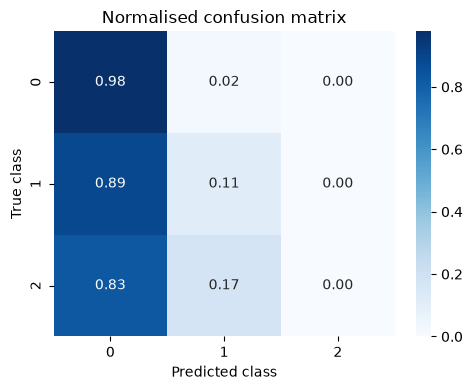

In [45]:
# Confusion-matrix heat-map (normalised row-wise)
cm  = confusion_matrix(y_test, y_pred, labels=[0,1,2])
cmn = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(5,4))
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["0","1","2"], yticklabels=["0","1","2"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalised confusion matrix")
plt.tight_layout()
plt.show()

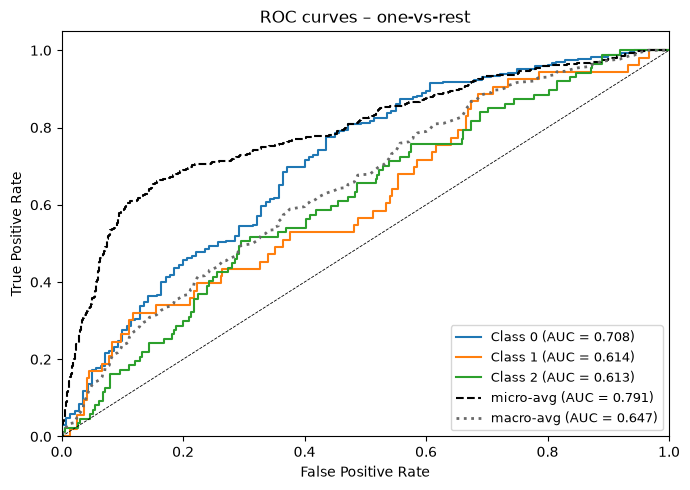

In [46]:
# ROC curves (one-vs-rest) + macro/micro averages
n_classes = 3
fpr = dict(); tpr = dict(); roc_auc = dict()

# one-vs-rest curves
for c in range(n_classes):
    fpr[c], tpr[c], _ = roc_curve((y_test == c).astype(int), y_proba[:, c])
    roc_auc[c] = auc(fpr[c], tpr[c])

# micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(
    pd.get_dummies(y_test).values.ravel(), y_proba.ravel()
)
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# macro-average (average the FPR points first, then AU-C)
all_fpr = np.unique(np.concatenate([fpr[c] for c in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for c in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[c], tpr[c])
mean_tpr /= n_classes
fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# ---------- Plot ----------
plt.figure(figsize=(7,5))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]  # default matplotlib palette

for c, col in zip(range(n_classes), colors):
    plt.plot(fpr[c], tpr[c], color=col,
             label=f"Class {c} (AUC = {roc_auc[c]:.3f})", lw=1.5)

# macro & micro
plt.plot(fpr["micro"], tpr["micro"], linestyle="--", color="black",
         label=f"micro-avg (AUC = {roc_auc['micro']:.3f})", lw=1.5)
plt.plot(fpr["macro"], tpr["macro"], linestyle=":", color="dimgray",
         label=f"macro-avg (AUC = {roc_auc['macro']:.3f})", lw=2)

plt.plot([0,1], [0,1], "k--", lw=0.6)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves – one-vs-rest")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

In [47]:
print("\nArea-under-curve (AUC) scores:")
auc_tbl = pd.DataFrame(
    {f"Class {c}": roc_auc[c] for c in range(n_classes)} |
    {"micro-avg": roc_auc["micro"], "macro-avg": roc_auc["macro"]},
    index=["AUC"]
).T
auc_tbl.style.format("{:.4f}")


Area-under-curve (AUC) scores:


,AUC
Class 0,0.7082
Class 1,0.6136
Class 2,0.6127
micro-avg,0.7907
macro-avg,0.6471


In [48]:
# ==================================================
# Walk-Forward (Rolling window) Validation Approach
# ==================================================

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report
import pandas as pd

n_splits = 5  # change this for more/less rolling windows
tscv = TimeSeriesSplit(n_splits=n_splits)

fold_metrics = []

print(f"\nWalk-forward validation ({n_splits} splits) on label: {best_label}\n")
for fold, (train_idx, test_idx) in enumerate(tscv.split(df_ta)):
    train = df_ta.iloc[train_idx]
    test = df_ta.iloc[test_idx]
    X_train, y_train = train[feature_cols], train[best_label]
    X_test, y_test = test[feature_cols], test[best_label]

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=3,
        n_jobs=-1,
        eval_metric='mlogloss',
        seed=42,
        use_label_encoder=False
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    metrics = {
        "fold": fold+1,
        "start": test.index[0],
        "end": test.index[-1],
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "precision_macro": precision_score(y_test, y_pred, average="macro"),
        "recall_macro": recall_score(y_test, y_pred, average="macro"),
    }
    fold_metrics.append(metrics)
    print(f"Fold {fold+1}: {test.index[0]} to {test.index[-1]}")
    print(f"  Accuracy: {metrics['accuracy']:.4f}, F1-macro: {metrics['f1_macro']:.4f}\n")

# summary DataFrame
results_df = pd.DataFrame(fold_metrics)
display(results_df)

print("\nMean (±std) metrics across folds:")
for m in ["accuracy", "f1_macro", "precision_macro", "recall_macro"]:
    print(f"{m:15}: {results_df[m].mean():.4f} ± {results_df[m].std():.4f}")


Walk-forward validation (5 splits) on label: label_la4_th0.010



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:17:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:17:42] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 1: 2012-12-24 00:00:00 to 2015-09-28 00:00:00
  Accuracy: 0.4647, F1-macro: 0.2981

Fold 2: 2015-09-29 00:00:00 to 2018-07-05 00:00:00
  Accuracy: 0.7597, F1-macro: 0.4243



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:17:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 3: 2018-07-06 00:00:00 to 2021-04-09 00:00:00
  Accuracy: 0.4043, F1-macro: 0.3453



...

Fold 4: 2021-04-12 00:00:00 to 2024-01-11 00:00:00
  Accuracy: 0.4835, F1-macro: 0.3799



c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:17:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 5: 2024-01-12 00:00:00 to 2026-10-16 00:00:00
  Accuracy: 0.6230, F1-macro: 0.3459



,fold,start,end,accuracy,f1_macro,precision_macro,recall_macro
0,1,2012-12-24,2015-09-28,0.464748,0.298074,0.308406,0.397878
1,2,2015-09-29,2018-07-05,0.759712,0.424330,0.487431,0.412768
2,3,2018-07-06,2021-04-09,0.404317,0.345336,0.422217,0.385756
3,4,2021-04-12,2024-01-11,0.483453,0.379865,0.417614,0.410001
4,5,2024-01-12,2026-10-16,0.623022,0.345937,0.442931,0.380101



Mean (±std) metrics across folds:
accuracy       : 0.5471 ± 0.1433
f1_macro       : 0.3587 ± 0.0468
precision_macro: 0.4157 ± 0.0660
recall_macro   : 0.3973 ± 0.0144


In [49]:
%pip install nbconvert
!jupyter nbconvert --to script main.ipynb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
[NbConvertApp] Converting notebook main.ipynb to script
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
[NbConvertApp] Writing 16408 bytes to main.py
